# Hierarchical Models and Partial Pooling

**What you'll learn**

- The many-groups problem — one metric across ~40 stores with wildly different traffic —
  and the three estimators every senior DS should be able to contrast on a whiteboard:
  **complete pooling**, **no pooling** (per-group MLE), and **partial pooling**
  (a hierarchical Bayesian model in PyMC).
- The classic **shrinkage plot** — small stores pulled hard toward the grand mean, large
  stores barely moving — and *why* precision-weighted compromise is the right answer.
- Out-of-sample proof that shrinkage wins: truth-RMSE and held-out log loss across the
  three estimators, sliced by store size.
- **Ranking fairly**: why "sort by observed rate" crowns small-sample flukes, and how
  posterior-based ranking (probability of being in the top decile) fixes it.
- The wider family: borrowing strength, the **James–Stein** dominance result, the exact
  correspondence with frequentist **mixed-effects models** (statsmodels `MixedLM` BLUPs),
  and **hierarchical A/B analysis** that shrinks per-segment treatment effects.

**Why it matters in interviews**

- "Some segments/geos have tiny samples — how do you report per-segment results?" is one of
  the most reliable senior-DS screens. "Hierarchical model / partial pooling", said with
  mechanics, separates seniors from script-runners.
- "Rank sellers by rating when some have 3 reviews" (and its cousins: best store, best ad
  creative, best hospital) is a classic estimation-under-noise question.
- Explaining shrinkage to a PM — without the word "prior" — is a communication test that
  interviewers run deliberately.
- Mixed-effects vs hierarchical Bayes vs regularization: interviewers probe whether you see
  these as one idea or three disconnected tools.

Everything is simulated so ground truth is known and every claim is checkable. The general
PyMC workflow (prior predictive checks, diagnostics, model criticism) is
[02_pymc_workflow.ipynb](./02_pymc_workflow.ipynb)'s topic — here we use it and focus on the
*hierarchical* ideas. Hand-picked priors for a single A/B test are
[01_bayesian_ab_testing.ipynb](./01_bayesian_ab_testing.ipynb); this notebook is where those
priors come from when you have many related experiments: the hierarchy *learns the prior
from the other groups*.

In [1]:
import logging
import warnings

warnings.filterwarnings("ignore", category=FutureWarning, module="arviz")  # arviz import noise

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
import statsmodels.formula.api as smf
from scipy import stats
from scipy.special import logit, expit

logging.getLogger("pymc").setLevel(logging.ERROR)  # sampler chatter off; we print diagnostics ourselves

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)

## 1. The many-groups problem: one metric, 40 stores

A retail chain wants per-store **conversion** (transactions / visitors) for next quarter's
planning: which stores over/under-perform, who gets the intervention budget, whose manager
gets the bonus. Traffic is wildly unequal — flagship city stores see tens of thousands of
visitors a month, mall kiosks see a few dozen.

We simulate a month of data with known truth:

- each store's true rate lives on the logit scale: $\operatorname{logit}(p_i) \sim
  N(\operatorname{logit}(4.5\%),\ 0.40^2)$ — true rates roughly 2–9%, a realistic spread;
- traffic $n_i$ is lognormal across three orders of magnitude;
- we also simulate a *second* month from the same true rates as a **holdout** for
  out-of-sample validation later.

Three estimators of the vector $p_1, \dots, p_{40}$:

| estimator | formula | implicit claim |
|---|---|---|
| **complete pooling** | $\hat p_i = \sum x_j / \sum n_j$ for all $i$ | "all stores are identical" |
| **no pooling** | $\hat p_i = x_i / n_i$ (per-store MLE) | "stores share nothing" |
| **partial pooling** | posterior mean under a hierarchical model | "stores differ, but are drawn from a common population" |

In [2]:
S = 40
store_id = np.array([f"S{i:02d}" for i in range(1, S + 1)])

n = np.round(np.exp(rng.normal(6.6, 1.5, S))).astype(int).clip(min=25)   # monthly visitors
p_true = expit(rng.normal(logit(0.045), 0.40, S))                        # true conversion rates
x = rng.binomial(n, p_true)                                              # month 1 (training)
x_hold = rng.binomial(n, p_true)                                         # month 2 (holdout)

mle = x / n
p_pool = x.sum() / n.sum()

stores = pd.DataFrame({"store": store_id, "n": n, "conv": x,
                       "MLE %": 100 * mle, "true %": 100 * p_true}).set_index("store")
print(f"traffic: min {n.min():,}, median {int(np.median(n)):,}, max {n.max():,} visitors "
      f"({n.max() / n.min():,.0f}x spread)")
print(f"pooled rate (complete pooling): {p_pool:.2%};  true rates span "
      f"{p_true.min():.2%}..{p_true.max():.2%}")
print(f"per-store MLEs span {mle.min():.2%}..{mle.max():.2%} — wider than the truth")
lo, hi = np.argmin(mle), np.argmax(mle)
print(f"observed extremes: {store_id[lo]} at {mle[lo]:.2%} (n={n[lo]}, true {p_true[lo]:.2%}); "
      f"{store_id[hi]} at {mle[hi]:.2%} (n={n[hi]}, true {p_true[hi]:.2%})")
extreme6 = np.concatenate([np.argsort(mle)[:3], np.argsort(mle)[-3:]])
print(f"traffic of the 6 stores at the observed extremes: {np.sort(n[extreme6]).tolist()} "
      f"(median store: {int(np.median(n))})\n")
print("five smallest and five largest stores:")
print(pd.concat([stores.sort_values("n").head(5), stores.sort_values("n").tail(5)]))

traffic: min 39, median 764, max 18,260 visitors (468x spread)
pooled rate (complete pooling): 4.23%;  true rates span 2.35%..7.89%
per-store MLEs span 1.26%..8.05% — wider than the truth
observed extremes: S21 at 1.26% (n=557, true 2.35%); S18 at 8.05% (n=174, true 7.89%)
traffic of the 6 stores at the observed extremes: [154, 174, 433, 557, 620, 1365] (median store: 764)

five smallest and five largest stores:
           n  conv   MLE %  true %
store                             
S05       39     2  5.1282  4.7049
S06      104     3  2.8846  4.8912
S02      154     3  1.9481  5.5316
S18      174    14  8.0460  7.8923
S16      203     7  3.4483  3.5209
S04     3013   161  5.3435  4.9164
S14     3987   169  4.2388  3.9814
S36     3998   244  6.1031  5.8478
S23     4600   230  5.0000  4.7882
S31    18260   511  2.7985  2.7510


The pathology is already visible: the observed rates span 1.3%–8.1% while the true rates
span 2.4%–7.9% — the league table *overdisperses*, and five of the six stores at its
observed extremes have below-median traffic. The casualties are concrete: store S02 (154
visitors) posts 1.9%, second-worst on the board, while its true rate of 5.5% is *above*
the chain average. Each MLE is unbiased on its own; but across many groups the extremes of
the table are dominated by small-sample noise — the same order-statistics effect behind
the winner's curse and regression to the mean
([../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb)).

## 2. The hierarchical model: partial pooling in PyMC

The model that encodes "stores differ, but are drawn from a common population":

$$\mu \sim N(\operatorname{logit}(0.05),\ 1.5^2), \qquad
  \sigma \sim \text{HalfNormal}(1),$$
$$\operatorname{logit}(p_i) = \mu + \sigma z_i, \quad z_i \sim N(0,1), \qquad
  x_i \sim \text{Binomial}(n_i,\ p_i).$$

Two things to notice:

- The **population parameters $\mu, \sigma$ are learned from the data** — this is what makes
  it more than "pick a prior": the 39 other stores *are* the prior for store $i$, with the
  amount of pooling ($\sigma$) estimated, not assumed. When $\sigma \to 0$ the model collapses
  to complete pooling; when $\sigma \to \infty$ it collapses to no pooling. Partial pooling
  is not a compromise you choose — it's one the data chooses.
- We write $\operatorname{logit}(p_i) = \mu + \sigma z_i$ (the **non-centered
  parameterization**) rather than $\operatorname{logit}(p_i) \sim N(\mu, \sigma)$ — with small
  groups this avoids the funnel geometry that produces divergences (demonstrated in
  Pitfall 1; general sampler diagnostics are
  [02_pymc_workflow.ipynb](./02_pymc_workflow.ipynb)).

MCMC is kept light (1,000 tune + 1,000 draws, 2 chains) — this posterior is easy.

In [3]:
with pm.Model() as store_model:
    mu = pm.Normal("mu", logit(0.05), 1.5)
    sigma = pm.HalfNormal("sigma", 1.0)
    z = pm.Normal("z", 0.0, 1.0, shape=S)
    p = pm.Deterministic("p", pm.math.invlogit(mu + sigma * z))
    pm.Binomial("obs", n=n, p=p, observed=x)
    idata = pm.sample(draws=1000, tune=1000, chains=2, cores=1, target_accept=0.9,
                      random_seed=42, progressbar=False,
                      idata_kwargs={"log_likelihood": False})

div = int(idata.sample_stats.diverging.sum())
print(az.summary(idata, var_names=["mu", "sigma"]).loc[:, ["mean", "sd", "hdi_3%", "hdi_97%",
                                                           "ess_bulk", "r_hat"]])
print(f"\ndivergences: {div}")
print(f"population mean rate: expit(mu) posterior mean = "
      f"{expit(idata.posterior['mu']).mean().item():.2%}")
print(f"true population parameters: mu = {logit(0.045):.3f}, sigma = 0.40")

        mean     sd  hdi_3%  hdi_97%  ess_bulk  r_hat
mu    -3.064  0.062  -3.178   -2.947     465.0    1.0
sigma  0.339  0.057   0.235    0.443     549.0    1.0

divergences: 0
population mean rate: expit(mu) posterior mean = 4.47%
true population parameters: mu = -3.055, sigma = 0.40


In [4]:
post_p = az.extract(idata, var_names="p").values      # (S, n_samples)
post_mean = post_p.mean(axis=1)
post_sd = post_p.std(axis=1)

est = {"complete pooling": np.full(S, p_pool),
       "no pooling (MLE)": mle,
       "partial pooling": post_mean}

print("the three estimates for the five smallest stores, and the largest (%):")
cmp = pd.DataFrame({k: 100 * v for k, v in est.items()},
                   index=store_id).assign(**{"true %": 100 * p_true, "n": n})
print(pd.concat([cmp.sort_values("n").head(5), cmp.sort_values("n").tail(1)]).round(2))

the three estimates for the five smallest stores, and the largest (%):
     complete pooling  no pooling (MLE)  partial pooling  true %      n
S05              4.23              5.13             4.74    4.70     39
S06              4.23              2.88             4.05    4.89    104
S02              4.23              1.95             3.54    5.53    154
S18              4.23              8.05             6.34    7.89    174
S16              4.23              3.45             4.01    3.52    203
S31              4.23              2.80             2.83    2.75  18260


Sampling is clean (no divergences, $\hat R \approx 1$), and the hyperparameters are
recovered well ($\mu$: −3.06 vs true −3.06; $\sigma$: 0.34 vs true 0.40). For the smallest
stores the posterior mean sits between the population mean (~4.5%) and their own MLE, and
the less data a store has, the closer it sits to the population. One subtlety worth
noticing: the hierarchy's anchor is the **population mean of stores** (expit($\mu$) ≈ 4.5%,
each store one vote), not the visitor-weighted pooled rate (4.2%, dominated by megastores)
— "a typical store" and "a typical visitor's store" are different quantities, and complete
pooling estimates the latter. The interpolation itself has a closed-form intuition: on
the logit scale the posterior mean is approximately a **precision-weighted average**,

$$\hat\theta_i \approx w_i \,\hat\theta_i^{\text{MLE}} + (1 - w_i)\,\hat\mu,
\qquad w_i = \frac{\sigma^2}{\sigma^2 + s_i^2},$$

where $s_i^2$ is the sampling variance of store $i$'s MLE. Big store: $s_i^2 \ll \sigma^2$,
$w_i \to 1$, keep your data. Tiny store: $s_i^2 \gg \sigma^2$, $w_i \to 0$, borrow the
population's. Every method in this notebook — hierarchical Bayes, BLUPs, James–Stein,
empirical Bayes — is a variation on this one formula.

## 3. The classic shrinkage plot

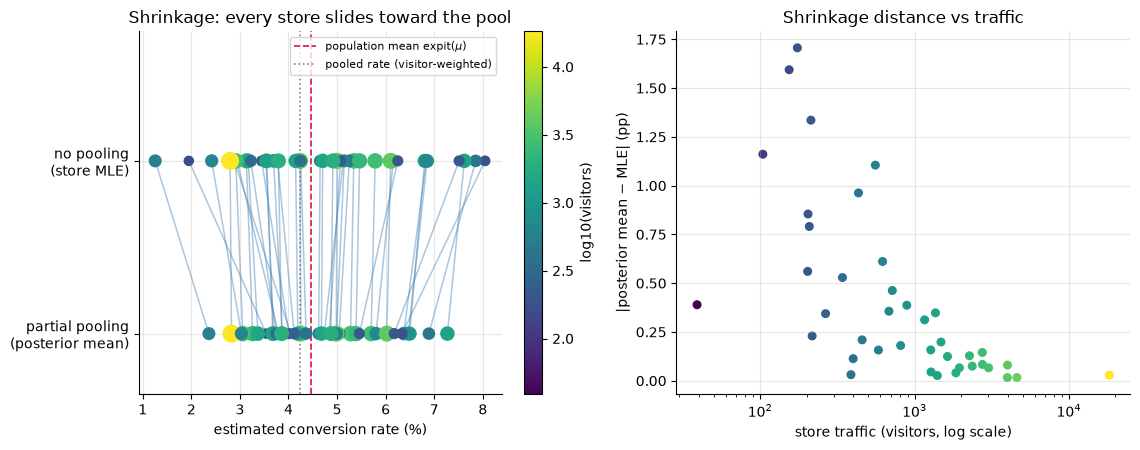

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
logn = np.log10(n)
sizes = 14 + 130 * (logn - logn.min()) / (logn.max() - logn.min())

ax = axes[0]
for i in range(S):
    ax.plot([100 * mle[i], 100 * post_mean[i]], [1, 0], color="steelblue", alpha=0.45, lw=1.1)
sc = ax.scatter(100 * mle, np.ones(S), s=sizes, c=logn, cmap="viridis", zorder=3)
ax.scatter(100 * post_mean, np.zeros(S), s=sizes, c=logn, cmap="viridis", zorder=3)
pop_mean = float(expit(idata.posterior["mu"]).mean())
ax.axvline(100 * pop_mean, color="crimson", ls="--", lw=1.2, label="population mean expit($\\mu$)")
ax.axvline(100 * p_pool, color="gray", ls=":", lw=1.2, label="pooled rate (visitor-weighted)")
ax.set_yticks([0, 1])
ax.set_yticklabels(["partial pooling\n(posterior mean)", "no pooling\n(store MLE)"])
ax.set_ylim(-0.35, 1.75)                                  # headroom so the legend clears the dots
ax.set_xlabel("estimated conversion rate (%)")
ax.set_title("Shrinkage: every store slides toward the pool")
ax.legend(fontsize=8, loc="upper right")
cb = fig.colorbar(sc, ax=ax)
cb.set_label("log10(visitors)")

ax = axes[1]
ax.scatter(n, 100 * np.abs(post_mean - mle), s=30, c=logn, cmap="viridis")
ax.set_xscale("log")
ax.set_xlabel("store traffic (visitors, log scale)")
ax.set_ylabel("|posterior mean − MLE| (pp)")
ax.set_title("Shrinkage distance vs traffic")
plt.show()

Read it like an interviewer would want you to:

- **Small stores (dark, small dots) travel far** — a percentage point or more, some
  crossing other stores on the way. Their MLEs were mostly noise, and the model knows it
  because their binomial standard errors are huge relative to the estimated between-store
  spread $\sigma$.
- **Large stores (bright, big dots) barely move** — the 18k-visitor flagship shifts by
  ~0.03pp. With that much data, the likelihood
  overwhelms the population prior — exactly the "priors wash out" behavior from
  [01_bayesian_ab_testing.ipynb](./01_bayesian_ab_testing.ipynb), except here the prior was
  *earned* from the other stores rather than asserted.
- The right panel is the $w_i$ formula made visible: shrinkage distance decays smoothly
  with $n_i$. Nobody set a threshold like "trust stores with $n>1000$"; the precision
  weighting does it continuously.

## 4. Out-of-sample validation: shrinkage isn't a philosophy, it wins

Two scorecards, neither available to a real analyst but both available to us:

- **RMSE against the true rates** (the simulation superpower);
- **log loss on the held-out month** — the real-world check: which estimate best predicts
  *next* month's conversions? We score it two ways: per visitor (dominated by big stores,
  where everyone agrees) and per store (equal weight — the view that matters if you make one
  decision per store).

In [6]:
def holdout_logloss(p_est, per_store=False):
    """Bernoulli log loss of estimates against the holdout month."""
    q = np.clip(p_est, 1e-12, 1 - 1e-12)
    ll_i = -(x_hold * np.log(q) + (n - x_hold) * np.log1p(-q))   # nats per store
    return (ll_i / n).mean() if per_store else ll_i.sum() / n.sum()


scored = est | {"oracle (true rates)": p_true}
rows = []
for name, e in scored.items():
    rows.append({"estimator": name,
                 "RMSE vs truth (pp)": 100 * np.sqrt(np.mean((e - p_true) ** 2)),
                 "holdout log loss / visitor": holdout_logloss(e),
                 "holdout log loss / store": holdout_logloss(e, per_store=True)})
val = pd.DataFrame(rows).set_index("estimator")
print(val.round(4))

ll_cols = ["holdout log loss / visitor", "holdout log loss / store"]
excess = 1000 * (val[ll_cols] - val.loc["oracle (true rates)", ll_cols])
excess.columns = ["excess/visitor (millinats)", "excess/store (millinats)"]
print("\nholdout log loss in excess of the oracle (lower = closer to the best achievable):")
print(excess.drop("oracle (true rates)").round(2))

terc = pd.qcut(n, 3, labels=["small third", "middle third", "large third"])
by_size = pd.DataFrame({
    name: [100 * np.sqrt(np.mean((e[terc == t] - p_true[terc == t]) ** 2))
           for t in terc.categories]
    for name, e in est.items()}, index=terc.categories)
print("\nRMSE vs truth (pp) by traffic tercile:")
print(by_size.round(3))

                     RMSE vs truth (pp)  holdout log loss / visitor  holdout log loss / store
estimator                                                                                    
complete pooling                 1.3045                      0.1708                    0.1825
no pooling (MLE)                 1.0368                      0.1698                    0.1822
partial pooling                  0.7109                      0.1697                    0.1814
oracle (true rates)              0.0000                      0.1695                    0.1811

holdout log loss in excess of the oracle (lower = closer to the best achievable):
                  excess/visitor (millinats)  excess/store (millinats)
estimator                                                             
complete pooling                        1.32                      1.44
no pooling (MLE)                        0.30                      1.08
partial pooling                         0.15                      0.3

The verdict:

- **Partial pooling wins every scorecard**: truth-RMSE 0.71pp vs 1.04 (no pooling) and
  1.30 (complete pooling), and the lowest holdout log loss on both weightings — its
  per-store excess over the oracle (~0.3 millinats) is roughly a quarter of no pooling's.
- **It beats both rivals in every traffic tercile** — that's the adaptivity: among large
  stores it is close to the MLE (0.32 vs 0.38pp; there was little to fix, $w_i \approx 1$),
  among small stores the MLE's error runs ~50% higher (1.49 vs 1.01pp). No pooling and complete
  pooling each have a tercile where they embarrass themselves; partial pooling has none.
- **Complete pooling is worst overall** because stores genuinely differ: it loses most
  where rates are precisely measured and genuinely far from the pool (0.87 vs 0.32pp in the
  large tercile).
- The estimators are nearly indistinguishable on *visitor-weighted* log loss (big stores
  dominate, and everyone agrees about big stores) but separate clearly per store: aggregate
  metrics hide small-group failures. That is a general reporting lesson, not a Bayesian one.

## 5. Ranking fairly: who is actually the best store?

Now the question leadership actually asks: "send me the top stores." Naive answer: sort by
observed rate. The top of that list is systematically polluted by small-sample flukes —
ranking by MLE rewards *variance*, not performance. The posterior fixes it: for each
posterior draw, rank the stores' *latent* rates; report each store's **probability of being
in the true top decile** (top 4 of 40). This folds each store's uncertainty into the rank
itself: a 39-visitor store can have a high observed rate but never a high
$P(\text{top 4})$, because its posterior is too wide to be confident about anything.

In [7]:
D = post_p.T                                        # (draws, S) posterior of latent rates
fourth_best = np.sort(D, axis=1)[:, -4][:, None]    # per-draw 4th-largest latent rate
p_top4 = (D >= fourth_best).mean(axis=0)            # P(store in top decile)

true_top4 = set(np.argsort(-p_true)[:4])
rank_df = pd.DataFrame({"n": n, "conv": x, "MLE %": 100 * mle, "post mean %": 100 * post_mean,
                        "P(top decile)": p_top4, "true %": 100 * p_true,
                        "truly top4": [i in true_top4 for i in range(S)]}, index=store_id)

naive_pick = np.argsort(-mle)[:4]
bayes_pick = np.argsort(-p_top4)[:4]

print("naive top-4 (sort by observed rate):")
print(rank_df.iloc[naive_pick].round(3))
print("\nposterior top-4 (sort by P(top decile)):")
print(rank_df.iloc[bayes_pick].round(3))

print(f"\ntruly-top-4 stores captured: naive {len(set(naive_pick) & true_top4)}/4, "
      f"posterior {len(set(bayes_pick) & true_top4)}/4")
for name, pick in [("naive", naive_pick), ("posterior", bayes_pick)]:
    hold_rate = x_hold[pick].sum() / n[pick].sum()
    print(f"{name} picks: mean true rate {p_true[pick].mean():.2%}, "
          f"holdout pooled rate {hold_rate:.2%}, median traffic {int(np.median(n[pick])):,}")

naive top-4 (sort by observed rate):
        n  conv  MLE %  post mean %  P(top decile)  true %  truly top4
S18   174    14  8.046        6.340          0.377   7.892        True
S26   433    34  7.852        6.890          0.579   6.078       False
S29  1365   104  7.619        7.271          0.804   6.228        True
S39   213    16  7.512        6.176          0.324   5.706       False

posterior top-4 (sort by P(top decile)):
        n  conv  MLE %  post mean %  P(top decile)  true %  truly top4
S29  1365   104  7.619        7.271          0.804   6.228        True
S26   433    34  7.852        6.890          0.579   6.078       False
S01  1161    79  6.804        6.492          0.412   5.965       False
S07   890    61  6.854        6.467          0.404   6.259        True

truly-top-4 stores captured: naive 2/4, posterior 2/4
naive picks: mean true rate 6.48%, holdout pooled rate 6.27%, median traffic 323
posterior picks: mean true rate 6.13%, holdout pooled rate 6.03%, median tr

Read the two lists carefully — this single month is honest about both the win and the
limits:

- The naive list is ordered by luck as much as by quality: its median pick has a few
  hundred visitors, and two of its four picks (S26, S39) are not truly top-decile — they
  observed 7.9% and 7.5% on true rates of 6.1% and 5.7%. The holdout month duly deflates
  the naive picks to a pooled 6.3% (regression to the mean, on schedule).
- The posterior list shifts toward stores with *evidence* (median traffic ~3x higher) and
  its confidence is calibrated: even its leader gets $P(\text{top 4}) = 0.80$, not a
  coronation.
- It is not magic, though: in this particular month both lists capture 2 of the true top 4.
  Partial pooling demoted S18 — a 174-visitor store that happens to *genuinely* be
  excellent (true 7.9%) — because one small month cannot distinguish a true outlier from a
  fluke. Shrinkage buys you average-case correctness, not clairvoyance.

So let's measure the average case, since a single simulated month has too much luck in it:
replay the whole exercise over 400 fresh months. MCMC per month would be wasteful — for a
beta-binomial hierarchy, empirical Bayes with method-of-moments hyperparameters (pooled
mean $m$, prior strength $\kappa$) gives closed-form per-store posteriors
$\mathrm{Beta}(\kappa m + x_i,\ \kappa(1-m) + n_i - x_i)$, the fast industrial version of
Section 2's model.

In [8]:
r_mc = np.random.default_rng(123)
mc = []
for _ in range(400):
    n_ = np.round(np.exp(r_mc.normal(6.6, 1.5, S))).astype(int).clip(min=25)
    p_ = expit(r_mc.normal(logit(0.045), 0.40, S))
    x_ = r_mc.binomial(n_, p_)
    order_true = np.argsort(-p_)
    true4 = set(order_true[:4])
    oracle_rate = p_[order_true[:4]].mean()
    naive4 = np.argsort(-(x_ / n_))[:4]
    m = x_.sum() / n_.sum()                                   # EB by method of moments
    tau2 = max(np.mean((x_ / n_ - m) ** 2) - m * (1 - m) * np.mean(1 / n_), 1e-8)
    kappa = m * (1 - m) / tau2 - 1
    Dd = r_mc.beta(kappa * m + x_, kappa * (1 - m) + n_ - x_, size=(400, S))
    fourth = np.sort(Dd, axis=1)[:, -4][:, None]
    ptop = (Dd >= fourth).mean(axis=0)
    eb4 = np.argsort(-ptop)[:4]
    mc.append([oracle_rate - p_[naive4].mean(), oracle_rate - p_[eb4].mean(),
               len(set(naive4) & true4), len(set(eb4) & true4),
               naive4[0] in true4, eb4[0] in true4, np.median(n_[naive4]), np.median(n_[eb4])])
mc = np.array(mc)

print("400 replays of the ranking exercise (pick 4 of 40 stores):")
print(f"  shortlist regret vs perfect pick:  naive {100 * mc[:, 0].mean():.2f}pp, "
      f"posterior {100 * mc[:, 1].mean():.2f}pp "
      f"({100 * (1 - mc[:, 1].mean() / mc[:, 0].mean()):.0f}% less)")
print(f"  true-top-4 stores captured (of 4): naive {mc[:, 2].mean():.2f}, "
      f"posterior {mc[:, 3].mean():.2f}")
print(f"  #1 pick truly in the top decile:   naive {mc[:, 4].mean():.0%}, "
      f"posterior {mc[:, 5].mean():.0%}")
print(f"  median traffic of picked stores:   naive {np.median(mc[:, 6]):,.0f}, "
      f"posterior {np.median(mc[:, 7]):,.0f}")

400 replays of the ranking exercise (pick 4 of 40 stores):
  shortlist regret vs perfect pick:  naive 0.62pp, posterior 0.44pp (30% less)
  true-top-4 stores captured (of 4): naive 2.67, posterior 2.81
  #1 pick truly in the top decile:   naive 77%, posterior 97%
  median traffic of picked stores:   naive 584, posterior 989


The averages settle it. The headline number is the last comparison but one: when you must
name a single "best store", the naive argmax is a store outside the true top decile about
one month in four; the posterior pick is wrong 3% of the time. The shortlist regret
(conversion given up relative to a perfect pick) drops by about a third. And the mechanism
is visible in the traffic column: naive ranking systematically over-picks small stores —
it rewards variance — while the posterior demands evidence proportional to the claim.

Two practical notes for the "rank sellers / hospitals / creatives" family of problems:

- The **ranking metric should match the decision**. $P(\text{top decile})$ is right for
  "shortlist candidates for an award/investigation"; expected rank or posterior mean is
  right for a league table; $P(\text{best})$ (Exercise 2) is right for picking a single
  winner — and is far more conservative than people expect.
- A common non-Bayesian shortcut ranks by the **lower confidence bound** of each group's
  rate (e.g. Wilson lower bound for "sort by rating"). It is a decent approximation to the
  same idea — penalize uncertainty — but it has a fixed, arbitrary penalty and no notion of
  the population; partial pooling calibrates the penalty from the data.

## 6. Borrowing strength: James–Stein and mixed-effects cousins

**Why does this work at all?** Each store's MLE is unbiased, and we replaced it with a
*biased* estimate — yet got uniformly better accuracy. The deep reason is that we are not
estimating one parameter; we are estimating forty *simultaneously*, and the loss that
matters is the total. Bias each estimate a little toward the pack, and the variance saved
swamps the bias paid, as long as the groups are related enough that the pack mean is
informative. Each store gives up a bit of its own identity to make the ensemble much better
— "borrowing strength".

**The James–Stein connection.** This isn't just Bayesian self-congratulation; it's a
frequentist theorem. Stein (1956) and James & Stein (1961) proved that for estimating $K
\ge 3$ normal means under total squared error, the MLE is **inadmissible**: the James–Stein
estimator, which shrinks every observation toward the grand mean by a data-estimated factor
$\big(1 - \tfrac{(K-3)\hat\sigma^2}{\sum_k (x_k - \bar x)^2}\big)$, has lower total MSE *for
every possible configuration of the true means* — even if the means are unrelated
quantities. Efron & Morris (1975) reframed it as **empirical Bayes**: James–Stein is
exactly the normal-normal hierarchical posterior mean with hyperparameters estimated from
the data, which is why their famous demo (predicting season batting averages from 45
at-bats, beating the MLE by ~3x in total error) looks exactly like our store problem.
Exercise 3 replicates the dominance result. The one caveat worth knowing: plug-in empirical
Bayes treats $\hat\mu, \hat\sigma$ as known, so its *intervals* run slightly narrow compared
to full Bayes, which propagates hyperparameter uncertainty — a small effect with 40 groups,
a big one with 8.

**The mixed-effects connection.** Frequentist statistics ships the same estimator under a
different brand: the random-intercept **mixed model** $y_{ij} = \beta_0 + u_i +
\varepsilon_{ij}$, $u_i \sim N(0, \tau^2)$. REML estimates the variance components, and the
predicted random effects (**BLUPs**) are precisely the precision-weighted shrinkage
$\hat u_i = w_i(\bar y_i - \hat\beta_0)$ with $w_i = \tau^2 / (\tau^2 + \sigma^2 / m_i)$.
Same math, point estimates instead of posteriors. We verify on a continuous metric —
average order value (AOV) across the same stores, one row per order:

In [9]:
TAU_AOV, SIG_AOV, GRAND_AOV = 6.0, 25.0, 60.0
u_true = rng.normal(0.0, TAU_AOV, S)                      # true store effects on AOV
frames = [pd.DataFrame({"store": sid, "aov": GRAND_AOV + u_true[i] + rng.normal(0, SIG_AOV, m)})
          for i, (sid, m) in enumerate(zip(store_id, x)) if m > 0]
aov = pd.concat(frames, ignore_index=True)
print(f"orders: {len(aov):,} across {aov['store'].nunique()} stores "
      f"(stores with 0 conversions contribute no rows)")

mlm = smf.mixedlm("aov ~ 1", aov, groups=aov["store"]).fit(reml=True)
tau2_hat, sig2_hat = float(mlm.cov_re.iloc[0, 0]), float(mlm.scale)
beta0 = float(mlm.params["Intercept"])
print(f"REML variance components: tau^2 = {tau2_hat:.1f} (true {TAU_AOV**2:.0f}), "
      f"sigma^2 = {sig2_hat:.0f} (true {SIG_AOV**2:.0f}); grand mean {beta0:.2f}")

blup = pd.Series({k: float(v.iloc[0]) for k, v in mlm.random_effects.items()})
g = aov.groupby("store")["aov"].agg(["mean", "size"])
w = tau2_hat / (tau2_hat + sig2_hat / g["size"])
check = pd.DataFrame({"orders": g["size"], "raw dev": g["mean"] - beta0,
                      "BLUP (MixedLM)": blup, "w x raw dev (by hand)": w * (g["mean"] - beta0),
                      "shrink weight w": w})
sel = pd.concat([check.sort_values("orders").head(3), check.sort_values("orders").tail(3)])
print("\nBLUP = precision-weighted shrinkage, verified (3 smallest / 3 largest stores):")
print(sel.round(2))

orders: 2,794 across 40 stores (stores with 0 conversions contribute no rows)
REML variance components: tau^2 = 54.2 (true 36), sigma^2 = 640 (true 625); grand mean 58.91

BLUP = precision-weighted shrinkage, verified (3 smallest / 3 largest stores):
     orders  raw dev  BLUP (MixedLM)  w x raw dev (by hand)  shrink weight w
S05       2   -14.18           -2.05                  -2.05             0.14
S02       3    -8.94           -1.81                  -1.81             0.20
S06       3    21.89            4.43                   4.43             0.20
S23     230   -13.67          -13.00                 -13.00             0.95
S36     244     6.36            6.07                   6.07             0.95
S31     511    -0.59           -0.57                  -0.57             0.98


The hand-computed $w_i (\bar y_i - \hat\beta_0)$ matches `MixedLM`'s BLUPs to rounding, and
the weights tell the same story as Section 3: stores with two or three orders keep 14–20%
of their raw deviation, the largest stores keep 95–98%. **When an interviewer asks
"hierarchical Bayes or mixed models?", the senior answer is: same estimator, different
uncertainty accounting** — `MixedLM`/`lme4` give you fast REML point machinery and BLUPs;
the Bayesian version adds full posteriors (needed for ranking probabilities like Section 5)
and honest uncertainty when groups or data are few. Ridge regression is the same idea once
more — shrinkage toward zero with the penalty playing the role of $\sigma^2/\tau^2$ (see
[../01_statistical_foundations/03_regression_the_workhorse.ipynb](../01_statistical_foundations/03_regression_the_workhorse.ipynb)).

## 7. Hierarchical A/B: shrinking per-segment treatment effects

The same machinery, pointed at experimentation. An A/B test ships a checkout change; the PM
asks for the lift **by country**. Twelve markets, traffic from 120,000 users/arm (US) down
to 600 (SE). Ground truth: every market's true lift is drawn from
$N(+0.25\text{pp},\ 0.08\text{pp}^2)$ — a genuinely positive effect with mild heterogeneity.

[../02_ab_testing/01_ab_test_end_to_end.ipynb](../02_ab_testing/01_ab_test_end_to_end.ipynb)
covers the *testing* discipline for segments (pre-registration, interaction tests, the
post-hoc fishing trap). Partial pooling is the *estimation* complement: when you must
report a number per segment, shrink the noisy per-segment differences toward the pooled
effect. We use the classic two-stage ("8 schools") form — per-segment effect estimates
$\hat d_s$ with known standard errors $se_s$, then a hierarchy on the true effects:

$$\hat d_s \sim N(\theta_s, se_s^2), \qquad \theta_s = \mu + \tau z_s, \quad z_s \sim N(0,1).$$

In [10]:
seg_names = np.array(["US", "DE", "GB", "FR", "BR", "IN", "JP", "CA", "AU", "MX", "NL", "SE"])
G = len(seg_names)
n_seg = np.array([120_000, 90_000, 60_000, 40_000, 25_000, 18_000,
                  12_000, 8_000, 5_000, 2_500, 1_200, 600])          # users per arm
base_seg = expit(rng.normal(logit(0.04), 0.30, G))                    # control conversion
lift_true = rng.normal(0.25, 0.08, G)                                 # true lift, pp

xa = rng.binomial(n_seg, base_seg)
xb = rng.binomial(n_seg, base_seg + lift_true / 100)
pa, pb = xa / n_seg, xb / n_seg
d_hat = 100 * (pb - pa)                                               # observed lift, pp
se_hat = 100 * np.sqrt(pa * (1 - pa) / n_seg + pb * (1 - pb) / n_seg)
z_seg = d_hat / se_hat

naive = pd.DataFrame({"users/arm": n_seg, "control %": 100 * pa, "lift pp": d_hat,
                      "se pp": se_hat, "z": z_seg,
                      "p": 2 * stats.norm.sf(np.abs(z_seg)),
                      "true lift pp": lift_true}, index=seg_names)
print(f"naive per-segment readout (true lift is +{lift_true.min():.2f}..+{lift_true.max():.2f}pp "
      "— positive everywhere):")
print(naive.round(3))

naive per-segment readout (true lift is +0.11..+0.42pp — positive everywhere):
    users/arm  control %  lift pp  se pp      z      p  true lift pp
US     120000      3.550    0.214  0.077  2.795  0.005         0.271
DE      90000      2.866    0.316  0.081  3.910  0.000         0.285
GB      60000      3.527    0.307  0.109  2.821  0.005         0.416
FR      40000      3.680    0.030  0.133  0.225  0.822         0.182
BR      25000      3.172    0.488  0.162  3.004  0.003         0.319
IN      18000      3.694    0.072  0.200  0.362  0.718         0.267
JP      12000      5.575    0.292  0.300  0.973  0.331         0.124
CA       8000      4.012    0.537  0.320  1.679  0.093         0.312
AU       5000      8.880   -0.520  0.561 -0.926  0.354         0.351
MX       2500      4.040   -0.440  0.542 -0.812  0.417         0.181
NL       1200      3.250    1.500  0.799  1.876  0.061         0.249
SE        600      5.333   -2.500  1.140 -2.192  0.028         0.112


The naive table is a stakeholder-management minefield. The three smallest markets all show
*negative* lifts — and Sweden shows **−2.5pp with p = 0.028**: nominally *significant harm*,
on 600 users/arm, in a market whose true lift is +0.11pp. Someone will ask to "hold the
rollout in the markets where it hurts", on evidence that is pure noise (each tiny-market CI
spans several times the true effect; and with 12 segments, one nominally-significant fluke
is exactly what multiplicity predicts). NL's +1.5pp is the mirror image — a 6x overstatement
that would headline someone's promo doc. The hierarchical readout:

In [11]:
with pm.Model() as seg_model:
    mu_d = pm.Normal("mu", 0.0, 1.0)            # pooled lift, pp
    tau = pm.HalfNormal("tau", 0.5)             # cross-market sd of true lift, pp
    zg = pm.Normal("z", 0.0, 1.0, shape=G)
    theta = pm.Deterministic("theta", mu_d + tau * zg)
    pm.Normal("obs", theta, se_hat, observed=d_hat)
    idata_seg = pm.sample(draws=1000, tune=1000, chains=2, cores=1, target_accept=0.9,
                          random_seed=43, progressbar=False,
                          idata_kwargs={"log_likelihood": False})

th = az.extract(idata_seg, var_names="theta").values      # (G, n_samples)
th_mean, th_lo, th_hi = th.mean(1), np.percentile(th, 2.5, axis=1), np.percentile(th, 97.5, axis=1)
print(az.summary(idata_seg, var_names=["mu", "tau"]).loc[:, ["mean", "sd", "hdi_3%", "hdi_97%",
                                                             "ess_bulk", "r_hat"]])
print(f"divergences: {int(idata_seg.sample_stats.diverging.sum())}")

rmse_naive = np.sqrt(np.mean((d_hat - lift_true) ** 2))
rmse_shrunk = np.sqrt(np.mean((th_mean - lift_true) ** 2))
print(f"\nRMSE vs true segment lifts: naive {rmse_naive:.3f}pp, "
      f"partial pooling {rmse_shrunk:.3f}pp ({rmse_naive / rmse_shrunk:.1f}x better)")
print(f"P(theta_s > 0) range across segments: {np.min((th > 0).mean(1)):.2f}.."
      f"{np.max((th > 0).mean(1)):.2f}")
i_se = list(seg_names).index("SE")
print(f"SE, revisited: naive {d_hat[i_se]:+.2f}pp (p = "
      f"{2 * stats.norm.sf(abs(z_seg[i_se])):.3f}) -> shrunken {th_mean[i_se]:+.2f}pp "
      f"[{th_lo[i_se]:+.2f}, {th_hi[i_se]:+.2f}], P(positive) = {(th[i_se] > 0).mean():.2f} "
      f"(true {lift_true[i_se]:+.2f}pp)")

      mean     sd  hdi_3%  hdi_97%  ess_bulk  r_hat
mu   0.235  0.068   0.107    0.360     812.0    1.0
tau  0.111  0.091   0.000    0.271     457.0    1.0
divergences: 0

RMSE vs true segment lifts: naive 0.900pp, partial pooling 0.079pp (11.4x better)
P(theta_s > 0) range across segments: 0.90..1.00
SE, revisited: naive -2.50pp (p = 0.028) -> shrunken +0.20pp [-0.25, +0.48], P(positive) = 0.90 (true +0.11pp)


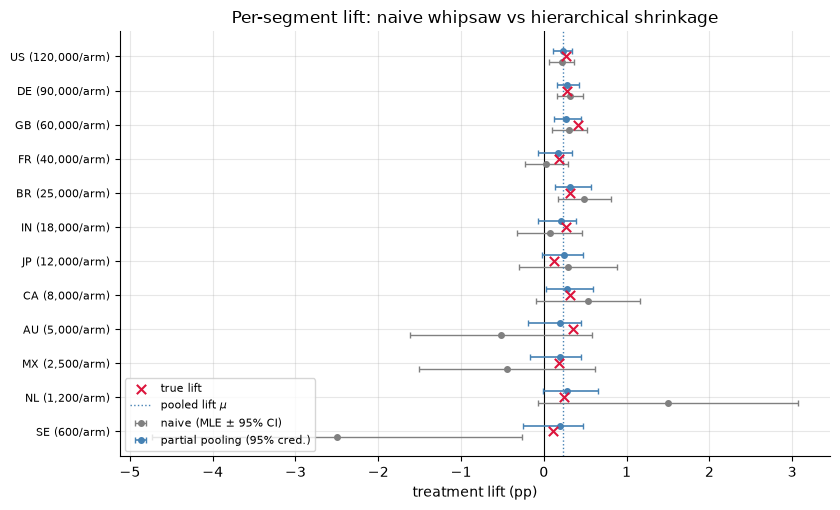

In [12]:
order = np.arange(G)                                     # already sorted by traffic
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.axvline(0, color="black", lw=0.8)
ax.errorbar(d_hat, order + 0.17, xerr=1.96 * se_hat, fmt="o", color="gray",
            ms=4, capsize=2, lw=1, label="naive (MLE ± 95% CI)")
ax.errorbar(th_mean, order - 0.17, xerr=[th_mean - th_lo, th_hi - th_mean], fmt="o",
            color="steelblue", ms=4, capsize=2, lw=1.2, label="partial pooling (95% cred.)")
ax.scatter(lift_true, order, marker="x", color="crimson", s=45, zorder=3, label="true lift")
ax.axvline(float(idata_seg.posterior["mu"].mean()), color="steelblue", ls=":", lw=1,
           label="pooled lift $\\mu$")
ax.set_yticks(order)
ax.set_yticklabels([f"{s} ({m:,}/arm)" for s, m in zip(seg_names, n_seg)], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("treatment lift (pp)")
ax.set_title("Per-segment lift: naive whipsaw vs hierarchical shrinkage")
ax.legend(fontsize=8, loc="lower left")
plt.show()

An 11x accuracy improvement, and the Sweden crisis dissolves: from "significant harm" to
"+0.2pp, probably positive like everyone else" — which is what's true. Note what shrinkage
does *not* do: it does not force segments to be equal — $\tau$'s posterior keeps real
heterogeneity on the table, and the big markets, with real information, are allowed to sit
away from $\mu$. The honest per-segment report is: **pooled lift $\mu \approx +0.24$pp
(94% HDI [+0.11, +0.36]); no market shows credible evidence of deviating from it;
small-market point estimates are shrunk accordingly.** If a segment *did* deviate
strongly (say a payment-method market where the feature breaks), its data would overwhelm
the pool and the model would leave it out there — partial pooling only "hides" effects that
the data cannot support.

This structure — many related experiments feeding a population model — is also the
principled source of the informative priors used in
[01_bayesian_ab_testing.ipynb](./01_bayesian_ab_testing.ipynb): your experiment archive
estimates the population of lifts, and each new test starts from that population instead of
from ignorance.

## 8. Business applications checklist

Reach for a hierarchical model whenever you see **many parallel small-sample estimates of
the same kind of quantity**:

- **Small geos / stores / branches**: per-unit KPIs for planning and league tables
  (Sections 1–5). Also per-warehouse defect rates, per-clinic outcomes, per-route demand.
- **New SKUs / cold start**: a new product's conversion or return rate starts at the
  posterior of its category and earns independence with data — the hierarchy *is* the
  cold-start prior. Same pattern for new ad creatives' CTR before a bandit takes over
  ([04_bandits_thompson.ipynb](./04_bandits_thompson.ipynb)).
- **Per-seller / per-driver / per-host ratings**: "4.9 stars from 3 reviews" vs "4.6 from
  2,000" — shrink toward the marketplace (or category) mean, rank by posterior quantities,
  not raw means (Section 5's machinery verbatim).
- **Per-segment treatment effects**: geo/platform/cohort breakdowns of experiments
  (Section 7), uplift by micro-segment
  ([../03_causal_inference/05_uplift_cate.ipynb](../03_causal_inference/05_uplift_cate.ipynb)).
- **Per-rep / per-agent conversion**: sales quota fairness, support-agent CSAT with very
  different ticket counts.

Buying decision in one line: if you're tempted to impose a minimum-sample cutoff ("only
show stores with 500+ visitors"), a hierarchical model is the principled version of that
instinct — it replaces the cliff with a continuous, data-calibrated dial.

## 9. Pitfalls

### Pitfall 1: the centered parameterization funnel

The mathematically identical "centered" model $\theta_s \sim N(\mu, \tau)$ samples badly
when groups are weakly informed: as $\tau \to 0$ the $\theta_s$ must collapse together, and
the joint posterior forms a funnel that NUTS cannot enter without divergences — biasing
$\tau$ upward and the shrinkage downward. Same data, same priors, both parameterizations:

There were 37 divergences after tuning. Increase `target_accept` or reparameterize.


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


              divergences  ESS(tau)  rhat(tau)  post mean tau (pp)
centered               37    46.260      1.052               0.134
non-centered            0   457.321      1.004               0.111


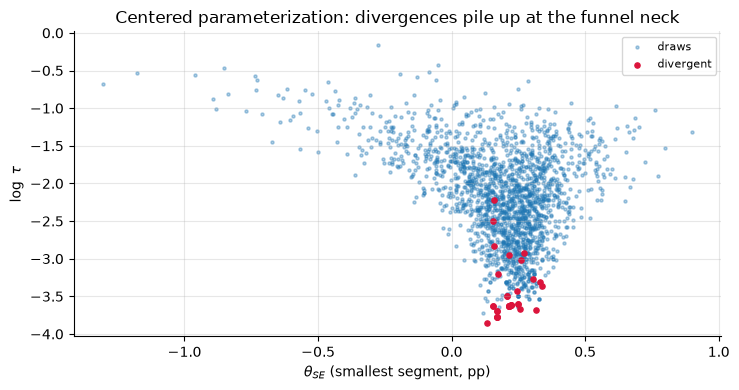

In [13]:
with pm.Model() as seg_centered:
    mu_c = pm.Normal("mu", 0.0, 1.0)
    tau_c = pm.HalfNormal("tau", 0.5)
    theta_c = pm.Normal("theta", mu_c, tau_c, shape=G)
    pm.Normal("obs", theta_c, se_hat, observed=d_hat)
    idata_cent = pm.sample(draws=1000, tune=1000, chains=2, cores=1, target_accept=0.9,
                           random_seed=44, progressbar=False,
                           idata_kwargs={"log_likelihood": False})

comp = pd.DataFrame({
    "divergences": [int(idata_cent.sample_stats.diverging.sum()),
                    int(idata_seg.sample_stats.diverging.sum())],
    "ESS(tau)": [float(az.ess(idata_cent, var_names="tau")["tau"]),
                 float(az.ess(idata_seg, var_names="tau")["tau"])],
    "rhat(tau)": [float(az.rhat(idata_cent, var_names="tau")["tau"]),
                  float(az.rhat(idata_seg, var_names="tau")["tau"])],
    "post mean tau (pp)": [float(idata_cent.posterior["tau"].mean()),
                           float(idata_seg.posterior["tau"].mean())],
}, index=["centered", "non-centered"])
print(comp.round(3))

fig, ax = plt.subplots(figsize=(7.5, 4.0))
tau_s = idata_cent.posterior["tau"].values.ravel()
th0_c = idata_cent.posterior["theta"].values[..., -1].ravel()   # smallest segment (SE)
div_mask = idata_cent.sample_stats.diverging.values.ravel()
ax.scatter(th0_c[~div_mask], np.log(tau_s[~div_mask]), s=5, alpha=0.35, label="draws")
ax.scatter(th0_c[div_mask], np.log(tau_s[div_mask]), s=14, color="crimson", label="divergent")
ax.set_xlabel(r"$\theta_{SE}$ (smallest segment, pp)")
ax.set_ylabel(r"$\log\ \tau$")
ax.set_title("Centered parameterization: divergences pile up at the funnel neck")
ax.legend(fontsize=8)
plt.show()

The centered run throws divergences concentrated at small $\tau$ (the funnel neck it cannot
enter) and delivers a fraction of the effective sample size for $\tau$. The non-centered
version samples the same posterior cleanly. Rule of thumb: **non-center by default when
groups are small or few**; center only when every group has strong data (then the funnel
disappears and centered can actually mix better). Full diagnostic workflow:
[02_pymc_workflow.ipynb](./02_pymc_workflow.ipynb).

### Pitfall 2: shrinking toward the wrong mean (exchangeability violation)

The hierarchy assumes groups are **exchangeable**: before seeing data, no group is special.
If group size *correlates with the true rate* — small rural stores genuinely convert better
than flagship megastores, new SKUs genuinely differ from established ones — then "shrink the
small guys toward the overall mean" imports a systematic bias: the overall mean belongs to
the big guys. We rebuild the store simulation with that confound (small stores truly
better) and fit the *same* hierarchical model that won every scorecard in Section 4, plus a
variant whose only change is a **group-level covariate**: standardized log traffic in the
population mean, so each store is shrunk toward *stores like it*.

In [14]:
S2 = 40
n2 = np.round(np.exp(rng.normal(6.6, 1.5, S2))).astype(int).clip(min=25)
z_logn = (np.log(n2) - np.log(n2).mean()) / np.log(n2).std()
p2 = expit(logit(0.05) - 0.30 * z_logn + rng.normal(0, 0.10, S2))   # small stores truly better
x2 = rng.binomial(n2, p2)
mle2 = x2 / n2


def fit_hier(with_covariate, seed):
    with pm.Model():
        mu0 = pm.Normal("mu0", logit(0.05), 1.5)
        sg = pm.HalfNormal("sigma", 1.0)
        zz = pm.Normal("z", 0.0, 1.0, shape=S2)
        eta = mu0 + sg * zz
        if with_covariate:
            beta = pm.Normal("beta", 0.0, 1.0)
            eta = eta + beta * z_logn
        p_ = pm.Deterministic("p", pm.math.invlogit(eta))
        pm.Binomial("obs", n=n2, p=p_, observed=x2)
        return pm.sample(draws=1000, tune=1000, chains=2, cores=1, target_accept=0.9,
                         random_seed=seed, progressbar=False,
                         idata_kwargs={"log_likelihood": False})


idata_flat2 = fit_hier(False, seed=45)
idata_cov2 = fit_hier(True, seed=46)
est_flat2 = az.extract(idata_flat2, var_names="p").values.mean(1)
est_cov2 = az.extract(idata_cov2, var_names="p").values.mean(1)

tercile2 = pd.qcut(np.log(n2), 3, labels=False)
small = tercile2 == 0
rows2 = {}
for name, e in [("no pooling (MLE)", mle2), ("hierarchical, no covariate", est_flat2),
                ("hierarchical + log-traffic covariate", est_cov2)]:
    rows2[name] = [100 * np.mean(e[small] - p2[small]),
                   100 * np.sqrt(np.mean((e[small] - p2[small]) ** 2)),
                   100 * np.sqrt(np.mean((e - p2) ** 2))]
bias = pd.DataFrame(rows2, index=["mean error, small tercile (pp)",
                                  "RMSE, small tercile (pp)", "RMSE, all stores (pp)"]).T
print(f"true mean rate: small tercile {p2[small].mean():.2%} vs "
      f"large tercile {p2[tercile2 == 2].mean():.2%} (small stores really are better)")
print(bias.round(3))
print("\ncovariate model recovers the confound (true slope -0.30, true sigma 0.10):")
print(az.summary(idata_cov2, var_names=["beta", "sigma"]).loc[:, ["mean", "sd", "hdi_3%",
                                                                  "hdi_97%", "r_hat"]])

true mean rate: small tercile 6.81% vs large tercile 3.83% (small stores really are better)
                                      mean error, small tercile (pp)  RMSE, small tercile (pp)  RMSE, all stores (pp)
no pooling (MLE)                                              -0.580                     1.495                  0.952
hierarchical, no covariate                                    -1.674                     1.721                  1.045
hierarchical + log-traffic covariate                          -0.506                     0.685                  0.419

covariate model recovers the confound (true slope -0.30, true sigma 0.10):
        mean     sd  hdi_3%  hdi_97%  r_hat
beta  -0.286  0.028  -0.336   -0.235    1.0
sigma  0.097  0.031   0.037    0.155    1.0


The failure is worth staring at. The MLE is noisy but roughly unbiased. The no-covariate
hierarchy trades that noise for a *systematic* −1.7pp bias on the small stores — it
confidently drags genuinely-good small stores toward a mean that describes the big ones —
and ends up **worse than no pooling overall** (RMSE 1.05 vs 0.95pp). Shrinkage is not a
free lunch; it is a bet on exchangeability, and here the bet is wrong. One group-level
covariate — `mu + beta * z_logn` — repairs it: the slope is recovered almost exactly, the
small-store bias collapses back to noise level, and overall RMSE (0.42pp) is now 2x better
than the MLE. **Exchangeability *conditional on covariates* is the assumption you should
defend in a design review**, and "shrink toward whom?" is the question to ask before
deploying any of this on sellers, geos, or SKUs (a new marketplace seller should be shrunk
toward *new sellers in their category*, not toward Amazon's incumbents).

### Pitfall 3: too few groups to learn $\tau$

The whole apparatus hinges on estimating the between-group sd. That estimate comes from
comparing groups to each other — with few groups (or per-group noise much larger than
$\tau$), the data barely pin it down, and your "learned" pooling is mostly your prior on
$\tau$. The profile likelihood of $\tau$ makes this visible without any MCMC:

our 12 segments                    argmax tau = 0.00pp;  relative likelihood at tau=0.3pp: 0.04, at tau=1pp: 0.00
the 4 smallest segments only       argmax tau = 0.77pp;  relative likelihood at tau=0.3pp: 0.84, at tau=1pp: 0.95
40 precise experiments (tau=0.15)  argmax tau = 0.13pp;  relative likelihood at tau=0.3pp: 0.00, at tau=1pp: 0.00


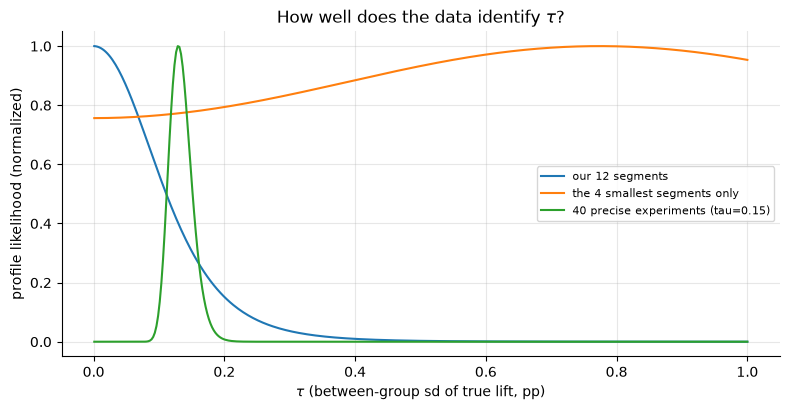

In [15]:
def tau_profile(y, s, tau_grid):
    """Profile log-likelihood of tau for the model y_g ~ N(mu, s_g^2 + tau^2), mu profiled out."""
    out = np.empty(len(tau_grid))
    for j, t in enumerate(tau_grid):
        v = s ** 2 + t ** 2
        mu_hat = np.sum(y / v) / np.sum(1 / v)
        out[j] = -0.5 * np.sum(np.log(v)) - 0.5 * np.sum((y - mu_hat) ** 2 / v)
    return out


tau_grid = np.linspace(1e-3, 1.0, 400)
big_program = {"our 12 segments": (d_hat, se_hat),
               "the 4 smallest segments only": (d_hat[-4:], se_hat[-4:])}
y40 = 0.25 + rng.normal(0.0, np.sqrt(0.15 ** 2 + 0.05 ** 2), 40)   # 40 precise experiments
big_program["40 precise experiments (tau=0.15)"] = (y40, np.full(40, 0.05))

fig, ax = plt.subplots(figsize=(8.0, 4.2))
for name, (y_, s_) in big_program.items():
    ll = tau_profile(y_, s_, tau_grid)
    rel = np.exp(ll - ll.max())
    ax.plot(tau_grid, rel, label=name)
    r_at = np.interp([0.3, 1.0], tau_grid, rel)
    print(f"{name:34s} argmax tau = {tau_grid[np.argmax(rel)]:.2f}pp;  relative likelihood "
          f"at tau=0.3pp: {r_at[0]:.2f}, at tau=1pp: {r_at[1]:.2f}")
ax.set_xlabel(r"$\tau$ (between-group sd of true lift, pp)")
ax.set_ylabel("profile likelihood (normalized)")
ax.set_title(r"How well does the data identify $\tau$?")
ax.legend(fontsize=8)
plt.show()

With only the 4 smallest segments the likelihood is essentially flat — every $\tau$ from 0
to 1pp sits within ~25% of the maximum, so whatever pooling strength you report is your
$\tau$ prior wearing a lab coat. Our full 12 segments *do* rule out $\tau > 0.3$pp, but
cannot distinguish $\tau = 0$ (identical markets) from $\tau = 0.15$pp (meaningful
heterogeneity) — and that unresolved range is exactly where shrinkage decisions live, which
is why Section 7's $\tau$ posterior leaned visibly on its HalfNormal(0.5) prior. Forty
precise experiments finally produce a likelihood peaked near the true 0.15. The
senior takeaways: (1) hierarchical models don't *fail* with few groups, but their pooling
strength is prior-driven, so run a sensitivity analysis on the $\tau$ prior exactly as you
would on any informative prior; (2) with fewer than ~5 groups, consider fixing the amount
of pooling on substantive grounds instead of pretending to learn it; (3) this is also why
empirical-Bayes plug-ins (the MoM $\hat\kappa$ in Section 5's simulation) get dangerous
with few groups — the moment estimate of $\tau$ is wildly unstable, and full Bayes at
least *tells* you the pooling strength is uncertain instead of silently picking one.

## Interview corner

**1. "Some segments in our experiment have tiny samples. How do you report per-segment
effects?"**
Never as raw per-segment estimates with stars — small-segment CIs whipsaw and produce
sign-flipped "insights" (Section 7). Strong answer: (a) pre-register few, mechanism-backed
segments and test *interactions*, not per-segment significance
([../02_ab_testing/01_ab_test_end_to_end.ipynb](../02_ab_testing/01_ab_test_end_to_end.ipynb));
(b) when per-segment numbers are demanded, fit a hierarchical model and report shrunken
effects plus the pooled effect $\mu$ and heterogeneity $\tau$; (c) state the decision rule
up front — "we act on segment deviations only if they're credible after pooling".

**2. "Explain partial pooling to a PM."**
No "prior", no "posterior": *"Each store's estimate is a weighted blend of its own data and
the chain's average. A store with lots of traffic keeps its own number; a store with 40
visitors mostly gets the chain average until it earns its own. The weights aren't chosen by
us — they come from how noisy each store is and how much stores genuinely differ."* Then a
concrete example ("this store showing 8% on 174 visitors is most likely a 6-ish store on a
good month") and the payoff: estimates that predict next month instead of embarrassing us.

**3. "How would you rank sellers by rating fairly, when review counts range from 3 to
3,000?"**
Shrink each seller's mean rating toward the population (better: their category) mean with
weight based on review count — hierarchical/empirical Bayes; then rank on a posterior
quantity matched to the use case: $P(\text{top decile})$ for badges, posterior mean for
default sort, $P(\text{rating} \ge 4.5)$ for a threshold policy. Mention the pragmatic
cousins (Laplace smoothing, Wilson lower bound) and the caveats: shrink toward the *right*
peer group (Pitfall 2), and watch incentives — sellers will notice new sellers being pinned
to the mean.

**4. "What's the James–Stein phenomenon and why should a practitioner care?"**
For 3+ means under total squared error, shrinking every estimate toward the grand mean
beats the per-group MLE for *any* true configuration — the MLE is inadmissible. Care
because: it licenses shrinkage as a frequentist optimality result, not a Bayesian taste;
it's the same estimator as empirical Bayes/BLUP/hierarchical posterior means; and it
quantifies the free lunch of estimating many related things jointly.

**5. "Hierarchical Bayes vs mixed-effects vs ridge — same or different?"**
Same core estimator, different wrappers. Random-intercept BLUP = precision-weighted
shrinkage = normal hierarchical posterior mean with REML plug-in hyperparameters (Section 6
verifies numerically). Ridge = MAP under a normal prior, shrinking toward zero instead of a
learned mean. Differences that matter: full Bayes propagates hyperparameter uncertainty
(few groups) and yields ranking probabilities; REML is fast and standard for longitudinal
data; ridge doesn't model group structure at all.

**6. "When would you NOT partially pool?"**
When groups aren't exchangeable and you can't fix it with group-level covariates (Pitfall
2); when the deliverable must be per-group *unbiased* (regulatory reporting, contractual
SLAs, incentive compensation — biased-toward-the-mean bonuses invite gaming and lawsuits);
when one group is qualitatively different (pool the 39 stores, not the airport duty-free);
and when groups are so large that pooling changes nothing but complexity.

**7. "Your hierarchical model says a small store is at 5.1%, the store's own data says
9%. The store manager objects. What do you say?"**
Show the track record, not the theology: across all small stores, raw rates from month 1
predicted month 2 worse than the shrunken rates did (Section 4's holdout table). Offer the
uncertainty interval — the model doesn't claim 5.1%, it claims 4–8% and will move as data
arrives. This is also why shrunken estimates should be labeled in dashboards: they are
forecasts of true performance, not accounting records of what happened.

## Key takeaways

- Many small-sample groups ⇒ per-group MLEs overdisperse: the extremes of the observed
  league table are mostly noise from the smallest groups.
- Partial pooling = precision-weighted blend of group data and population mean, with the
  blend weight $w_i = \sigma^2/(\sigma^2 + s_i^2)$ *learned from the data*. Complete and no
  pooling are its $\sigma \to 0$ / $\sigma \to \infty$ limits.
- The shrinkage plot is the diagnostic: small groups move a lot, big groups barely move. If
  everything moves equally, something's wrong.
- Shrinkage wins out of sample — best truth-RMSE and holdout log loss here — and wins
  *where it matters*: on the small groups. Aggregate metrics hide this; slice by group size.
- Rank on posterior quantities ($P(\text{top decile})$, $P(\text{best})$), never on raw
  rates; raw ranking rewards variance and the holdout month collects the debt.
- James–Stein: shrinkage dominates the MLE for 3+ means — a frequentist theorem, not a
  Bayesian preference. BLUPs from mixed models are the same estimator; ridge is its
  regression twin.
- Per-segment treatment effects are the killer app: shrink segment lifts toward the pooled
  lift; report $\mu$, $\tau$, and shrunken deviations instead of a grid of noisy stars.
- Use the non-centered parameterization for weakly-informed groups; defend exchangeability
  (shrink toward *whom*?) with group-level covariates; and with few groups, admit that the
  $\tau$ prior is doing the pooling.

## Exercises

**Exercise 1.** Using the normal-means model (known per-group noise $s = 1$, $G = 60$
groups), sweep the true between-group sd $\tau$ from 0 to 3. For each $\tau$, simulate many
datasets and compare the MSE of complete pooling, no pooling, and empirical-Bayes partial
pooling (method-of-moments $\hat\tau^2$). Verify that partial pooling ~matches complete
pooling at $\tau = 0$, ~matches no pooling at large $\tau$, and never does much worse than
the better of the two.

**Exercise 2.** For the store data, compute each store's posterior probability of being the
single best store, $P(\text{best})$. Compare the leader to the naive MLE argmax and to the
$P(\text{top decile})$ leader. Why is $P(\text{best})$ so much flatter than intuition
expects?

**Exercise 3.** Implement the James–Stein estimator and verify the dominance claim: for a
fixed vector of 40 true means, total squared error of JS < MLE, averaged over repeated
datasets. Then make the true means very dispersed and show the JS advantage disappears (but
never reverses).

          complete pooling  no pooling  EB partial pooling
true tau                                                  
0.00                 0.018       0.998               0.032
0.25                 0.077       0.996               0.089
0.50                 0.260       1.009               0.230
1.00                 0.991       1.000               0.525
1.50                 2.230       0.997               0.708
2.00                 3.920       0.993               0.809
3.00                 8.888       0.994               0.900


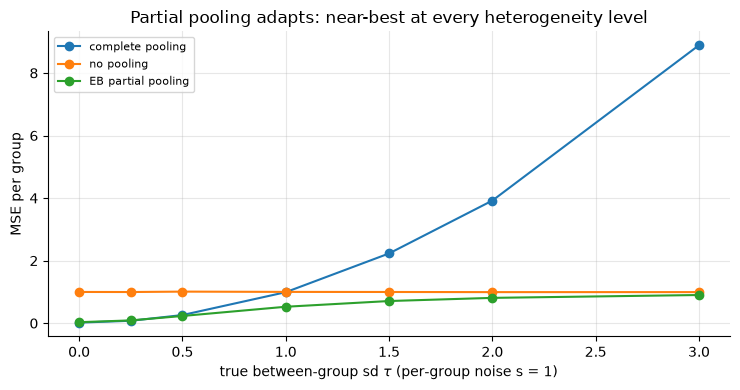

In [16]:
# --- Solution 1 ---
def ex1_mse(tau_true, r, G=60, sims=400):
    theta = r.normal(0.0, tau_true, (sims, G))
    y = theta + r.normal(0.0, 1.0, (sims, G))            # s = 1
    ybar = y.mean(axis=1, keepdims=True)
    tau2_hat = np.maximum(y.var(axis=1, ddof=1, keepdims=True) - 1.0, 0.0)
    w_eb = tau2_hat / (tau2_hat + 1.0)
    ests = {"complete pooling": np.broadcast_to(ybar, y.shape),
            "no pooling": y,
            "EB partial pooling": ybar + w_eb * (y - ybar)}
    return {k: np.mean((v - theta) ** 2) for k, v in ests.items()}


r1 = np.random.default_rng(7)
taus = np.array([0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0])
ex1 = pd.DataFrame([ex1_mse(t, r1) for t in taus], index=pd.Index(taus, name="true tau"))
print(ex1.round(3))

fig, ax = plt.subplots(figsize=(7.5, 4.0))
for c in ex1.columns:
    ax.plot(taus, ex1[c], "o-", label=c)
ax.set_xlabel(r"true between-group sd $\tau$ (per-group noise s = 1)")
ax.set_ylabel("MSE per group")
ax.set_title("Partial pooling adapts: near-best at every heterogeneity level")
ax.legend(fontsize=8)
plt.show()

At $\tau = 0$ EB nearly matches complete pooling (MSE 0.03 vs 0.02, against no pooling's
1.0); at $\tau = 3$ it approaches no pooling *and stays slightly below it* (0.90 vs 0.99 —
the James–Stein margin never fully disappears) while complete pooling is a disaster (8.9);
in between it tracks whichever is better, paying only a small adaptivity tax near the
crossover. That "never much worse, often much better" profile is what you're buying.

In [17]:
# --- Solution 2 ---
p_best = (D >= D.max(axis=1, keepdims=True)).mean(axis=0)
top = pd.DataFrame({"n": n, "MLE %": 100 * mle, "P(best)": p_best,
                    "P(top decile)": p_top4, "true %": 100 * p_true}, index=store_id)
print(top.sort_values("P(best)", ascending=False).head(5).round(3))
print(f"\nnaive argmax store: {store_id[np.argmax(mle)]} (n={n[np.argmax(mle)]}), "
      f"P(best) leader: {store_id[np.argmax(p_best)]}, "
      f"P(top decile) leader: {store_id[np.argmax(p_top4)]}")
print(f"max P(best) = {p_best.max():.2f} — no store is a confident #1")

        n  MLE %  P(best)  P(top decile)  true %
S29  1365  7.619    0.282          0.804   6.228
S26   433  7.852    0.218          0.579   6.078
S18   174  8.046    0.162          0.377   7.892
S39   213  7.512    0.100          0.324   5.706
S07   890  6.854    0.048          0.404   6.259

naive argmax store: S18 (n=174), P(best) leader: S29, P(top decile) leader: S29
max P(best) = 0.28 — no store is a confident #1


$P(\text{best})$ is flat because "best of 40" demands beating 39 rivals *simultaneously*,
and several stores have overlapping posteriors near the top — so even the strongest
candidate here sits below 30%. That flatness is information, not weakness: it says "don't
stake much on any single #1 claim". Decile membership is a far easier claim to certify,
which is why shortlist-style questions get crisper answers than winner-style questions.
(Thompson sampling in [04_bandits_thompson.ipynb](./04_bandits_thompson.ipynb) turns exactly
these $P(\text{best})$ numbers into an allocation policy.)

In [18]:
# --- Solution 3 ---
def js_estimate(y, s2=1.0):
    """James-Stein (positive part), shrinking toward the grand mean; rows = datasets."""
    ybar = y.mean(axis=1, keepdims=True)
    ss = ((y - ybar) ** 2).sum(axis=1, keepdims=True)
    c = np.maximum(1.0 - (y.shape[1] - 3) * s2 / ss, 0.0)
    return ybar + c * (y - ybar)


r3 = np.random.default_rng(11)
K, SIMS = 40, 3000
for spread, label in [(1.0, "related means (sd 1)"), (10.0, "dispersed means (sd 10)")]:
    theta3 = r3.normal(0.0, spread, K)                   # fixed truth for this scenario
    y3 = theta3 + r3.normal(0.0, 1.0, (SIMS, K))
    mse_mle = np.mean(((y3 - theta3) ** 2).sum(axis=1))
    mse_js = np.mean(((js_estimate(y3) - theta3) ** 2).sum(axis=1))
    print(f"{label:26s} total MSE: MLE {mse_mle:6.1f}, JS {mse_js:6.1f} "
          f"(JS/MLE = {mse_js / mse_mle:.2f})")

related means (sd 1)       total MSE: MLE   40.1, JS   18.7 (JS/MLE = 0.47)
dispersed means (sd 10)    total MSE: MLE   39.7, JS   39.3 (JS/MLE = 0.99)


With related means, JS cuts total squared error roughly in half; with wildly dispersed
means the shrinkage factor self-tunes toward zero and JS ≈ MLE — better in both worlds,
exactly as the theorem promises (for $K \ge 3$, under *total* squared error; individual
groups can be estimated worse, which is the price the small groups pay for the ensemble).